<a href="https://colab.research.google.com/github/zamoralinokevin-eng/Maestria-en-IA/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos_271753.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [76]:
#se importan librerias
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:
#se importan librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [78]:
#se lee el dataframe
df = pd.read_csv('drive/MyDrive/RegresionCategoricos/college.csv')

#se selecciona solo las columnas solicitadas
df = df[['salary', 'cost', 'location']]

#se convierte la variable location a tipo de dato categórico
df['location'] = df['location'].astype('category')

#se usa la instruccion describe en salary y cost
print('Valores estadísticos de salary y cost')
print(df[['salary', 'cost']].describe())

#se cuenta la cantidad de datos por categoría en location
print("\nConteo de datos por Location")
print(df['location'].value_counts())

#se convierte location usando one-hot encoding
df_encoded = pd.get_dummies(df, columns=['location'], drop_first=True, dtype=int)
print("\nPrimeras filas del Dataframe Codificado")
print(df_encoded.head())

Valores estadísticos de salary y cost
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000

Conteo de datos por Location
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64

Primeras filas del Dataframe Codificado
   salary    cost  location_NE  location_S  location_W
0  119000  189300            1           0           0
1  121000  189600            1           0           0
2  123000  188400            1           0           0
3  123000  188700            1           0           0
4  110000  194200            1           0           0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




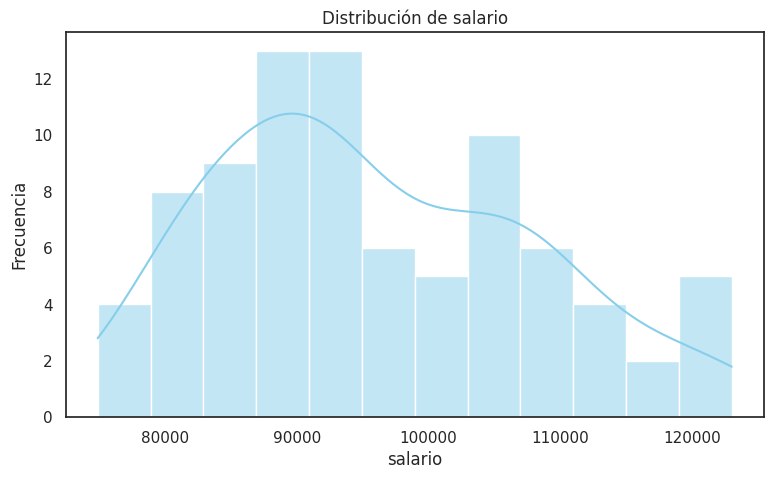

In [79]:
# Configuramos el estilo visual
sns.set_theme(style="white")

#se crea un histograma de Salary
plt.figure(figsize=(9, 5))
sns.histplot(df['salary'], kde=True, color='skyblue', bins=12)
plt.title('Distribución de salario')
plt.xlabel('salario')
plt.ylabel('Frecuencia')
plt.show()

##Discusión
En el histograma de salario se observa que los salarios se concentran principalmente en el rango de 85000 a 100000. Se ve que existe una distribución asimétrica con cola hacia la derecha lo que se puede interpretar que pocos centros educativos muestran salarios de hasta los 120000.

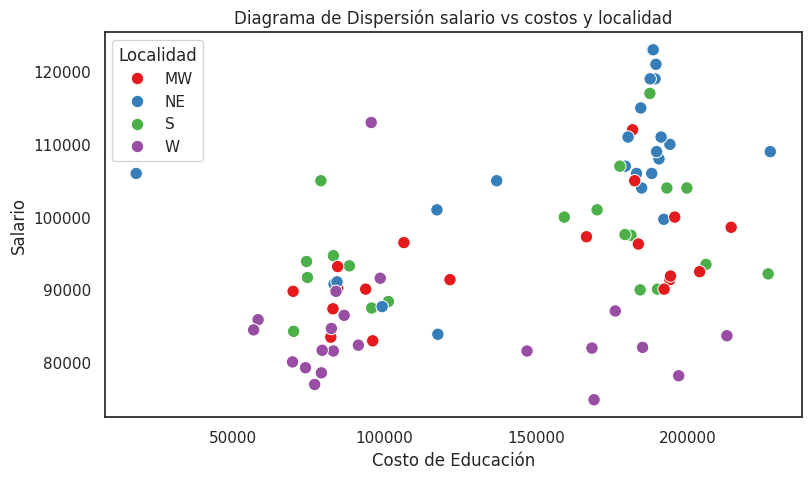

In [80]:
#se crea un diagrama de dispersión de Salary vs Cost
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='cost', y='salary', hue='location', palette='Set1', s=80)
plt.title('Diagrama de Dispersión salario vs costos y localidad')
plt.xlabel('Costo de Educación')
plt.ylabel('Salario')
plt.legend(title='Localidad')
plt.show()

##Discusión
En el diagram de dispersión, se aprecia una tendencia positiva con una distribución de puntos un poco dispersa a medida que se aleja de la línea. Según los colores, las instituciones del Noreste presentan los costos mas altos ya que estan en su mayoría en la esquina superior derecha, y de las del oeste estan en los valores mas bajos de costos, concentrándose en la esquina inferior izquierda. También las instituciones del oeste son las que presentan los salarios mas bajoscon un rango amplio de costos.

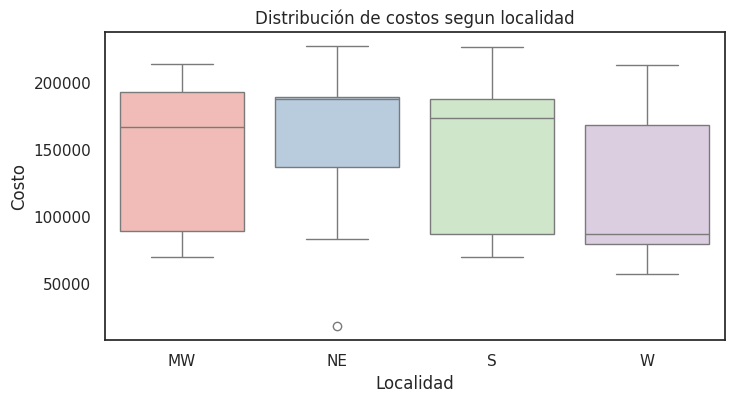

In [81]:
#se crea un boxplot de Cost por Localidad
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='location', y='cost', hue='location', palette='Pastel1')
plt.title('Distribución de costos segun localidad')
plt.xlabel('Localidad')
plt.ylabel('Costo')
plt.show()

##Discusión
En el diagrama de cajas se aprecia que la localidad de Noreste tiene la mediana mas alta pero con el menor rango de distribución de datos. Las cajas de medio oeste y sur presentan una distribución y mediana similar. Oeste presenta la mediana mas baja. Esto corrobora que los costos de Noreste son los mas altos en frecuencia y los del Oeste son los mas bajos por la mediana.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [82]:
#se usa One-Hot Encoding con K-1 en la columna location
df_encoded = pd.get_dummies(df, columns=['location'], drop_first=True, dtype=int)

#se separan las variables independientes X y la dependiente y
X = df_encoded.drop(columns=['salary'])
y = df_encoded['salary']

#se construye y entrena el modelo de Regresión Lineal
modelo_lr = LinearRegression()
modelo_lr.fit(X, y)

#se imprimen los resultados obtenidos
print(f"Intercepto: {modelo_lr.intercept_:.2f}")
print("\nCoeficientes de las variables independientes:")
for col, coef in zip(X.columns, modelo_lr.coef_):
    print(f" - {col}: {coef:.4f}")

# model = smf.ols('salary ~ cost + location', data=df).fit()
# print(model.summary())


Intercepto: 84988.72

Coeficientes de las variables independientes:
 - cost: 0.0605
 - location_NE: 12032.8197
 - location_S: 2800.3450
 - location_W: -7721.4201


##Interpretación
Al interpretar los valores obtenidos, tenemos que: Intercepto es 84988.72 lo que significa que es el salario estimado para un centro educativo que corresponde a la categoria eliminada de medio oeste MW cuando el costo de educación es cero. El coeficiente de cost es 0.0605 lo que significa que por cada dolar adicional que aumente el costo de educación, el salario incrementa en 0.06 dólares. El coeficiente de location NE tiene un salario estimado de 12032.82 mayor que el salario de MW en la que ambas tienen el mismo costo de educación. El coeficiente de location S tiene un salario de 2800.35 superior a MW en la que ambas tienen el mismo costo. El coeficiente de location W tiene un salario promedio de 7721.42 inferior a MW en la que ambos tienen el mismo costo.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

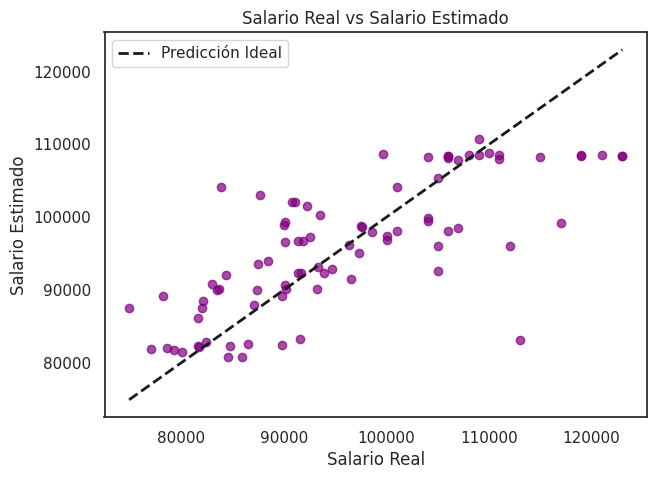

In [83]:
#se generan las predicciones (salario estimado) con el modelo entrenado
y_predict = modelo_lr.predict(X)

#se calculan los errores residuales (Valores Reales - Valores Predichos)
residuos = y - y_predict

#se guarda temporalmente en el dataframe para facilitar la graficación
df_graficos = df.copy()
df_graficos['predictions'] = y_predict
df_graficos['residuals'] = residuos

#se grafica salario real vs estimado
plt.figure(figsize=(7, 5))
plt.scatter(df_graficos['salary'], df_graficos['predictions'], color='purple', alpha=0.7)

#se grafica la línea de identidad ideal (Donde predicción == real)
plt.plot([df_graficos['salary'].min(), df_graficos['salary'].max()],
         [df_graficos['salary'].min(), df_graficos['salary'].max()],
         'k--', lw=2, label='Predicción Ideal')

plt.title('Salario Real vs Salario Estimado')
plt.xlabel('Salario Real')
plt.ylabel('Salario Estimado')
plt.legend()
plt.show()

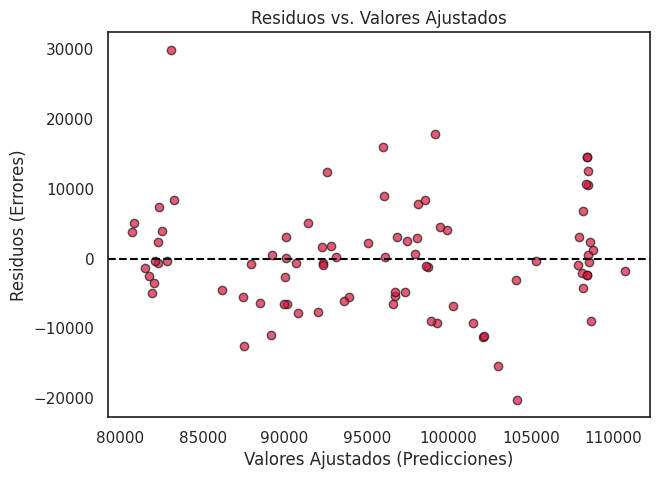

In [84]:
#se grafican los errores Residuales
plt.figure(figsize=(7, 5))
plt.scatter(df_graficos['predictions'], df_graficos['residuals'], color='crimson', alpha=0.7, edgecolors='k')

#se grafica la línea base en cero
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Residuos vs. Valores Ajustados')
plt.xlabel('Valores Ajustados (Predicciones)')
plt.ylabel('Residuos (Errores)')
plt.show()

##Discusión
En la gráfica de salario real vs salario estimado se ven que la nube de puntos esta cerca de la diagonal con poca dispersión de los datos. Esto confirma que el modelo predice bien la variable dependiente salario. En la gráfica de residuos, se observa una distribución aleatoria de la nube de puntos por arriba y debajo de la linea cero. Se aprecian varios valores lejanos a esta línea que se debe a los outliers encontrados anteriormente. No se aprecia la forma de embudo por lo que se puede decir que se cumple con la homocedasticidad. Se reafirma que el modelo lineal aprendido es adecuado para los datos.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [85]:
#se realizan los cálculos de rendimiento
mse_val = mean_squared_error(df_graficos['salary'], df_graficos['predictions'])
r2_val = r2_score(df_graficos['salary'], df_graficos['predictions'])

print(f"Mean Squared Error (MSE): {mse_val:,.2f}")
print(f"R² Score: {r2_val:.4f}")

Mean Squared Error (MSE): 60,480,269.15
R² Score: 0.5705


##Discusión
En los calculos de rendimiento del modelo, el R2 es de 0.5705 lo que se puede interpretar como las variables independientes cost y location dan razón del 57% de la variabilidad de los salarios en los centros educativos. Esto demuestra que el costo académico y la localidad infuyen en ingreso de salario.
El MSE mide el promedio de los errores al cuadrado calculando la distancia entre salario real y estimado. Como está al cuadrado, de allí el valor de 60480269.15 por lo que se recomienda el RMSE que es la raíz del MSE.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [86]:
#se contruye el modelo usando la librería statsmodel
model = smf.ols('salary ~ cost + location', data=df).fit()

#se realiza el análisis de varianza ANOVA
anova_results = sm.stats.anova_lm(model, typ=2)
print(f'Resultados del ANOVA \n{anova_results}')

Resultados del ANOVA 
                sum_sq    df          F        PR(>F)
location  4.071774e+09   3.0  21.121259  3.570975e-10
cost      7.878166e+08   1.0  12.259774  7.600629e-04
Residual  5.140823e+09  80.0        NaN           NaN


##Discusión
En el análisis de varianza se aprecia que las variables location y cost tienen valores de probabilidad pequeños de p menor a 0.05 lo que se puede interpretar que la localidad del centro educativo tiene una influencia estadísticamente significativa sobre el salario en la locación.